# 11. 입력 가용성 실험 — Baseline과 판정 규칙 검증

    정리일2026-11-12. 기존 TEP/PHM 파일은 읽기 전용으로 재사용했다. **이 노트북은 이미 수행한 실측 결과를 읽어 검증·표시하며 재학습이나 재추론을 실행하지 않는다.**

    실험의 순서는①기존 CNN Baseline 전체 재현②PHM V3 입력 불가 규칙 대조③실제 NaN 입력/윈도우 마스크 동등성④파일럿⑤전체 조건이다. 모델·분할·라벨·입력20×52·threshold·3연속 경보 규칙을 고정했다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/sensor_availability/config.json').exists())
OUT=ROOT/'reports/sensor_availability'
def js(name): return json.loads((OUT/name).read_text(encoding='utf-8'))
def table(name): return pd.read_csv(OUT/'tables'/name)
def show(frame,title):
    display(frame.style.hide(axis='index').set_caption(title).format(precision=5,na_rep='해당 없음')
            .set_properties(**{'padding':'6px 9px','text-align':'left'})
            .set_table_styles([{'selector':'caption','props':[('text-align','left'),('font-weight','bold')]},
                              {'selector':'th','props':[('background-color','#eef3f6'),('text-align','left')]}]))
def figure(name): display(Image(filename=str(OUT/'figures'/name)))
baseline=js('baseline.json')
phm=js('sources/phm_definition_audit.json')
full=table('full_summary.csv')
summary=table('summary_mean_sd.csv')

## 1. 전체 Test에서 기존 Baseline을 새로 재현한 결과

    중단 전 기존 최종 CNN을 로드하여 원본 Test의 유효9,880,500시점을 새로 추론했다. GPU 추론 실측67.17초이며 원본 보호 체크섬·후처리 시간은 제외한다. 저장된21개 확률과 차이0, 아래 지표와10,000개 이벤트별 검출·최초시각·지연이 일치했다. 하나라도 불일치하면 실험을 중단하도록 gate를 구현했다.

In [2]:
show(pd.DataFrame([
    ['모델',baseline['model']],['임계값',baseline['threshold']],
    ['ROC-AUC',baseline['detection_metrics']['detection_roc_auc']],['Detection F1',baseline['detection_metrics']['detection_f1']],
    ['전체 고장 실행',baseline['total_fault_runs']],['검출 실행',baseline['detected_fault_runs']],
    ['Run-level 검출률',baseline['run_detection_rate']],['검출 지연 중앙값(분)',baseline['median_delay_minutes']],
    ['정상 alarm episodes',baseline['normal_alarm_episodes']],['정상 관측지원시간(h)',baseline['normal_exposure_hours']],
    ['정상 episodes/h',baseline['normal_alarm_episodes_per_hour']],['새 추론 실측시간(s)',baseline['fresh_full_test_inference_seconds']]
],columns=['지표','실측 결과']),'원본 Test Baseline 재현 / 출처: baseline.json')
checks=table('baseline_reproduction.csv')
assert checks.passed.all()
show(checks,'기존 값과 새 재현 값 / 허용오차1e-10, 이벤트별 정확 일치')

지표,실측 결과
모델,CNN1D_Temporal_balanced_s42
임계값,0.96719
ROC-AUC,0.95393
Detection F1,0.92770
전체 고장 실행,10000
검출 실행,9851
Run-level 검출률,0.98510
검출 지연 중앙값(분),48.00000
정상 alarm episodes,705
정상 관측지원시간(h),23525.00000


metric,expected,reproduced,absolute_error,passed
detection_roc_auc,0.9539266359692902,0.9539266359692902,0.00000,True
detection_f1,0.9276972980979862,0.9276972980979862,0.00000,True
detection_precision,0.9970010449576019,0.9970010449576019,0.00000,True
detection_recall,0.86740225,0.86740225,0.00000,True
sample_false_alarm_rate,0.011099707524594523,0.011099707524594523,0.00000,True
per_event_detected,10000 original records,10000 fresh records,0.00000,True
per_event_first_detection_sample,10000 original records,10000 fresh records,0.00000,True
per_event_delay_minutes,10000 original records,10000 fresh records,0.00000,True
normal_alarm_episodes,705.0,705,0.00000,True
normal_exposure_hours,23525.0,23525.0,0.00000,True


## 2. PHM V3의 평가 불가능 조건 직접 대조

    PHM `evaluate()`는 이벤트별닫힌 사전 예측창`[tf-600,tf-60] raw`의 유효score anchor가1개 이상이면available=True,0개면NO_INPUT이다. B특징은현재센서+과거300raw 통계로서 lag≤12raw·같은세그먼트·coverage≥90% 등을 요구한다.

    TEP는고장 이후sample161~960의800시점에서 유효20×52입력이1개 이상이면평가 가능이다. 같은 것은**평가 구간에 예측 기회가0개인지**라는 의미이며, 전후 방향·시간 단위·입력 규칙은 다르다. PHM raw를 초/분으로 환산하지 않았다.

In [3]:
show(pd.DataFrame([
    ['전체 기록',phm['total_events']],['가용',phm['available_events']],['NO_INPUT',phm['unavailable_events']],
    ['검출',phm['detected_events']],['전체 검출률',phm['overall_detection_rate']],['가용 검출률',phm['conditional_detection_rate']]
],columns=['PHM 고정 운영점10','원표 검증 결과']),'PHM V3 stage6 실제 이벤트·요약표에서 검증')
ev=table('phm_verified_events.csv')
assert len(ev)==194 and ev.available.sum()==91 and ev.detected.sum()==33
assert np.array_equal(ev.available,ev.eligible_anchors>0)
show(ev.groupby('status').size().rename('이벤트 수').reset_index(),'PHM 상태별 실제 이벤트 수')

PHM 고정 운영점10,원표 검증 결과
전체 기록,194.00000
가용,91.00000
NO_INPUT,103.00000
검출,33.00000
전체 검출률,0.17010
가용 검출률,0.36264


status,이벤트 수
DETECTED,33
MISSED,58
NO_INPUT,103


## 3. 짧은 공백과 평가 불가능 실행을 구분

    주 실험은선택 실행의sample141~960을가려 고장 후 입력창이0개임을 보장한다. 이는TEP 고장 후40h를덮는 의도적인 검열 가정이며 PHM 실제 공백 길이 분포를 복원한 것이 아니다.

    짧은 공백(sample141~180)에서는sample200부터20개 연속 입력이복구돼761/800개 post-fault시점이남는다. 따라서이실행은95.125% **부분 가용**이며평가가능분모에포함한다. 유효창이딱1개·2개인경우도평가가능으로검증했다.

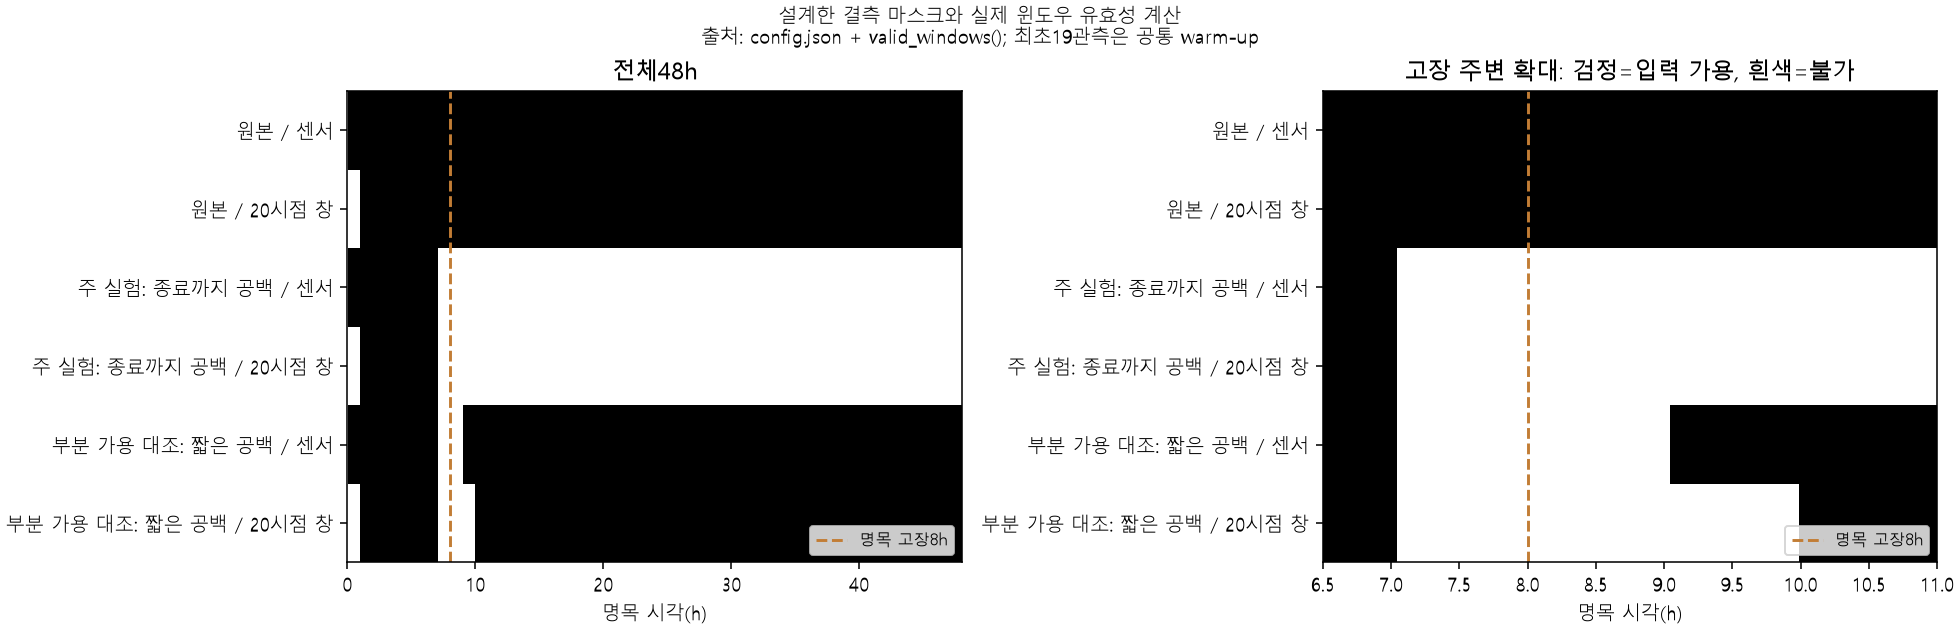

check,passed,valid_post_windows
window_mask_none,True,800.00000
window_mask_short_gap,True,761.00000
window_mask_full_censor,True,0.00000
window_mask_one_window,True,1.00000
window_mask_two_windows,True,2.00000
missing_points_break_alarm_streaks,True,해당 없음
no_future_dependency,True,해당 없음
fault_balanced_exact_nested_reproducible_selection,True,해당 없음


case,fault,run,valid_post_windows,surviving_inputs_exactly_identical,same_batch_predictions_exactly_identical,cached_prediction_max_probability_error,cache_error_note
none,1,1,800,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
none,9,1,800,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
none,15,3,800,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
short_gap,1,1,761,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
short_gap,9,1,761,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
short_gap,15,3,761,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
full_censor,1,1,0,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
full_censor,9,1,0,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
full_censor,15,3,0,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change
one_window,1,1,1,True,True,0.00000,different GPU batch packing may cause small rounding; no input/model change


In [4]:
figure('availability_masks.png')
mask=js('sources/mask_validation.json')
assert mask['passed']
show(pd.DataFrame(mask['checks']),'가용성·경보 연속성·미래참조·선정 재현성 검사')
show(table('mask_equivalence_checks.csv'),'실제 NaN 입력의 유효창과 마스크 필터링 비교')

남은입력창은원본과정확히같고,같은배치의예측도정확히같았다. 다른GPU배치포장에서는작은반올림차이가있을수있으며, 주실험은동일한기존예측을유효마스크로선택했다. 불가시점에정상/고장확률을만들지않았다. 경보계산중결측은연속성을끊는표식이며정상예측이아니다.

    ## 4. 진행 gate와 기존 파일 보존

In [5]:
pilot=js('sources/pilot_gate.json');preserve=js('sources/preservation_check.json')
assert pilot['passed'] and preserve['all_unchanged']
show(pd.DataFrame([
    ['Baseline gate',js('sources/baseline_gate.json')['passed']],['마스크 검증',mask['passed']],
    ['0/25/53.1% × seed42/43/44 파일럿',pilot['passed']],
    ['sklearn 파일럿 ROC-AUC 차이',pilot['sklearn_auc_difference']],['sklearn 파일럿 F1 차이',pilot['sklearn_f1_difference']],
    ['보존한 기존 TEP 파일',preserve['protected_TEP_files']],['보존한 PHM 참조파일',preserve['protected_PHM_source_files']],
    ['기존 보호파일 변경 없음',preserve['all_unchanged']]
],columns=['검사','결과']),'파일럿 통과 후에만 전체 조건으로 확장')

검사,결과
Baseline gate,True
마스크 검증,True
0/25/53.1% × seed42/43/44 파일럿,True
sklearn 파일럿 ROC-AUC 차이,0.00000
sklearn 파일럿 F1 차이,0.00000
보존한 기존 TEP 파일,147
보존한 PHM 참조파일,7
기존 보호파일 변경 없음,True
